# Notebook 2 de 4: planteo del problema y basal

Este notebook continúa la sesión del notebook 1. Antes de entrenar cualquier algoritmo se fija el marco de
comparación: el entorno y el split (M0), el basal (M1), la definición formal del problema con su criterio de
éxito (M2) y la estrategia de validación (M3).

In [1]:
# Continúa la sesión del notebook 01_EDA_y_seleccion (correrlo antes si el archivo no existe)
import joblib                 # se importa antes que dill para que joblib guarde los modelos con el pickle estándar
import dill
dill.load_session("artefactos_ml/estado_01.pkl")
dill.extend(False)            # deja el pickle estándar como estaba (lo usan joblib y pandas)
%matplotlib inline
print("Estado cargado desde artefactos_ml/estado_01.pkl")

Estado cargado desde artefactos_ml/estado_01.pkl


# 8. Aprendizaje de Máquina -  Modelado

Esta sección continúa el EDA (secciones 1 a 7, notebook 1) sobre **el mismo split** agrupado por paciente. Todo lo que
sigue se decide únicamente con el conjunto de entrenamiento: el test queda sellado hasta la evaluación
final (M9, notebook 4) y se usa una sola vez.

**Decisiones de diseño**

| Tema | Decisión |
|---|---|
| Objetivo | Determinar el reingreso en los 30 días siguientes al alta (`readmitted_temprano`). Sin hipótesis previas. |
| Momento de predicción | Al alta hospitalaria: las 18 variables seleccionadas se conocen hasta ese momento. |
| Métrica primaria | ROC-AUC (no requiere umbral). |
| Métricas secundarias | Recall, precisión, F1, exactitud balanceada y AUC-PR, con el umbral elegido sobre predicciones fuera de fold en train. |
| Costo de los errores | No cuantificado. No se define un punto de operación. |
| Basal | Regla de una sola variable: al menos k internaciones previas en el último año implica reingreso (k se calcula con el train; resultó 1). |
| Algoritmos | Regresión logística, Random Forest, CatBoost y XGBoost, todos contra el basal. |
| Validación | `StratifiedGroupKFold` de 5 folds agrupado por `patient_nbr` (semilla 42), solo sobre train. Repetición con otras semillas para los finalistas. |
| Fuga entre folds | Target encoding (agrupado por paciente), winsorización y escalado se aprenden dentro de cada fold. Las 18 variables quedan fijas. |
| Desbalance | Sin pesos de clase. El umbral se elige con predicciones fuera de fold. |
| Hiperparámetros | Carrera de mecanismos (grilla, aleatoria y Optuna) por algoritmo, con el mismo espacio, folds, métrica, semilla y presupuesto. |

## 8.0 M0: Enganche con el EDA

### 8.0.1 Entorno y reproducibilidad

In [2]:
import os, platform, time, json
from pathlib import Path
import scipy, sklearn, xgboost, catboost, optuna

SEMILLA = RANDOM_STATE                       # semilla global (42)
ARTEFACTOS = Path("artefactos_ml")           # índices, folds, configuración y registro de experimentos
ARTEFACTOS.mkdir(exist_ok=True)

versiones = pd.DataFrame({
    "componente": ["Python", "numpy", "pandas", "scipy", "scikit-learn", "xgboost", "catboost",
                   "optuna", "matplotlib", "seaborn"],
    "versión": [platform.python_version(), np.__version__, pd.__version__, scipy.__version__,
                sklearn.__version__, xgboost.__version__, catboost.__version__, optuna.__version__,
                mpl.__version__, sns.__version__],
})
versiones.to_csv(ARTEFACTOS / "versiones.csv", index=False)
print(f"Núcleos de CPU disponibles: {os.cpu_count()}  |  semilla global: {SEMILLA}")
versiones

Núcleos de CPU disponibles: 15  |  semilla global: 42


,componente,versión
0,Python,3.13.16
1,numpy,2.5.3
2,pandas,3.0.6
3,scipy,1.18.1
4,scikit-learn,1.9.1
5,xgboost,3.4.1
6,catboost,1.2.10
7,optuna,5.0.0
8,matplotlib,3.11.2
9,seaborn,0.13.2


### 8.0.2 Reproducción del split y test sellado

Se verifica que el split del EDA se reproduce (mismas filas y misma tasa de positivos) y se guardan sus
índices. Luego se **sella el test**: sus datos se guardan en un archivo y se eliminan de la memoria, de modo
que ninguna celda de modelado pueda leerlos por error. 

In [3]:
# --- Reproducción del split (los índices salen del EDA, no se vuelve a particionar) ---
es_train = data_set["_es_train"].to_numpy()
enc_train = data_set.loc[es_train, "encounter_id"].to_numpy()
enc_test = data_set.loc[~es_train, "encounter_id"].to_numpy()
grupos_test = data_set.loc[~es_train, "patient_nbr"].reset_index(drop=True)

assert len(set(grupos_train) & set(grupos_test)) == 0, "hay pacientes en train y en test"
assert len(enc_train) == 71583 and len(enc_test) == 30180, "el split no reproduce el del EDA"
print(f"Train: {len(enc_train)} filas, {grupos_train.nunique()} pacientes | "
      f"Test: {len(enc_test)} filas, {grupos_test.nunique()} pacientes | pacientes compartidos: 0")
print(f"Tasa de reingreso en train: {y_train_final.mean():.4f}")

# --- Valores crudos de las dos numéricas que se winsorizan: la winsorización se aprende dentro de cada fold ---
crudo = pd.read_csv("diabetic_data.csv", usecols=["encounter_id", "num_lab_procedures",
                                                  "num_medications"]).set_index("encounter_id")

VARS_NUM = list(cols_num_modelo)             # 4 numéricas
VARS_ORD = list(cols_ordinales)              # 4 ordinales
VARS_TE = list(cols_alta_cardinalidad)       # 7 nominales de alta cardinalidad (target encoding)
VARS_OHE = list(cols_baja_cardinalidad)      # 3 nominales de baja cardinalidad (one-hot)
VARS_18 = VARS_NUM + VARS_ORD + VARS_TE + VARS_OHE
assert len(VARS_18) == 18 and set(VARS_18) == set(variables_seleccionadas)


def marco_modelado(X, ids_encuentro, grupos):
    # Las 18 variables de la selección del EDA + `patient_nbr` (solo para agrupar; no es predictora).
    M = X[VARS_18].copy()
    M["num_lab_procedures"] = crudo.loc[ids_encuentro, "num_lab_procedures"].to_numpy()
    M["num_medications"] = crudo.loc[ids_encuentro, "num_medications"].to_numpy()
    M["patient_nbr"] = grupos.to_numpy()
    return M


Xm_train = marco_modelado(X_train, enc_train, grupos_train)
Xm_test = marco_modelado(X_test, enc_test, grupos_test)

# Control de alineación: las columnas crudas, recortadas al p99 de train del EDA, deben dar las del EDA
for c in ["num_lab_procedures", "num_medications"]:
    assert (Xm_train[c].clip(upper=X_train[c].max()) == X_train[c]).all(), f"desalineada: {c}"

# --- Guardar los índices del split y SELLAR el test ---
pd.to_pickle({"X": Xm_test, "y": y_test_final.reset_index(drop=True), "grupos": grupos_test,
              "encounter_id": enc_test}, ARTEFACTOS / "test_sellado.pkl")
(ARTEFACTOS / "split.json").write_text(json.dumps({
    "semilla": SEMILLA, "test_size": 0.30, "agrupado_por": "patient_nbr",
    "encounter_id_train": [int(v) for v in enc_train],
    "encounter_id_test": [int(v) for v in enc_test]}))

for nombre in ["X_test", "X_test_final", "X_test_reducido", "y_test_final", "y_test", "ohe_test",
               "Xm_test", "grupos_test", "enc_test", "X", "y", "data_set", "df_train"]:
    globals().pop(nombre, None)
assert not any(n in globals() for n in ["X_test", "X_test_reducido", "y_test_final", "Xm_test"])
print("Test sellado: guardado en artefactos_ml/test_sellado.pkl y eliminado de la memoria.")

Train: 71583 filas, 50060 pacientes | Test: 30180 filas, 21455 pacientes | pacientes compartidos: 0
Tasa de reingreso en train: 0.1127
Test sellado: guardado en artefactos_ml/test_sellado.pkl y eliminado de la memoria.


**Lectura.** El split del EDA se reproduce exactamente: 71.583 filas de train y 30.180 de test, sin pacientes
compartidos. A partir de acá ninguna celda tiene acceso al test.

### 8.0.3 Preprocesamiento dentro del Pipeline

Para que ninguna decisión use datos de validación, todo lo que se **aprende de los datos** se ajusta solo con
el train de cada fold: la winsorización al p99 de `num_lab_procedures` y `num_medications`, el target
encoding (suavizado m=20, con folds internos agrupados por paciente) y el escalado. La codificación ordinal y
el one-hot usan categorías fijas, que son un esquema y no un estadístico. Las 18 variables quedan tal como
las dejó la selección del EDA.

`race` no se imputa porque no está entre las 18 variables seleccionadas. La winsorización de los conteos
previos no afecta a las variables que entran al modelo, porque `number_emergency_disc` y
`number_inpatient_disc` agrupan los valores de 3 en adelante.

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold


class Winsorizador(BaseEstimator, TransformerMixin):
    # Recorta al percentil q (aprendido en el fit) solo las columnas indicadas por posición.
    def __init__(self, posiciones=(), q=0.99):
        self.posiciones, self.q = posiciones, q

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.techos_ = {j: np.quantile(X[:, j], self.q) for j in self.posiciones}
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)
        for j, techo in self.techos_.items():
            X[:, j] = np.minimum(X[:, j], techo)
        return X


class QuitarColumna(BaseEstimator, TransformerMixin):
    # Elimina una columna por posición (categoría de referencia del one-hot).
    def __init__(self, indice=0):
        self.indice = indice

    def fit(self, X, y=None):
        self.n_features_in_ = np.asarray(X).shape[1]
        return self

    def transform(self, X):
        return np.delete(np.asarray(X, dtype=float), self.indice, axis=1)


def _medias_suavizadas(y_fit, x_fit, media_global, m):
    agg = y_fit.groupby(x_fit.astype(object), observed=True).agg(["mean", "count"])
    return (agg["mean"] * agg["count"] + media_global * m) / (agg["count"] + m)


class CodificadorObjetivoAgrupado(BaseEstimator, TransformerMixin):
    # Target encoding out-of-fold con suavizado. La última columna recibida es `patient_nbr` y solo
    # sirve para agrupar los folds internos; no se devuelve.
    def __init__(self, suavizado=20, n_folds=5, semilla=42):
        self.suavizado, self.n_folds, self.semilla = suavizado, n_folds, semilla

    def fit(self, X, y):
        cats, y = X.iloc[:, :-1].reset_index(drop=True), pd.Series(np.asarray(y))
        self.media_global_ = float(y.mean())
        self.medias_ = {c: _medias_suavizadas(y, cats[c], self.media_global_, self.suavizado)
                        for c in cats.columns}
        return self

    def fit_transform(self, X, y):
        # Para las filas de entrenamiento se usa la codificación fuera de fold (no la del fit completo).
        cats, y = X.iloc[:, :-1].reset_index(drop=True), pd.Series(np.asarray(y))
        grupos = X.iloc[:, -1].to_numpy()
        self.fit(X, y)
        out = np.full(cats.shape, np.nan)
        folds = StratifiedGroupKFold(n_splits=self.n_folds, shuffle=True, random_state=self.semilla)
        for idx_fit, idx_apl in folds.split(cats, y, groups=grupos):
            for j, c in enumerate(cats.columns):
                medias = _medias_suavizadas(y.iloc[idx_fit], cats[c].iloc[idx_fit],
                                            self.media_global_, self.suavizado)
                out[idx_apl, j] = (cats[c].astype(object).iloc[idx_apl].map(medias)
                                   .astype(float).to_numpy())
        return np.where(np.isnan(out), self.media_global_, out)

    def transform(self, X):
        cats = X.iloc[:, :-1].reset_index(drop=True)
        out = np.column_stack([cats[c].astype(object).map(self.medias_[c]).astype(float).to_numpy()
                               for c in cats.columns])
        return np.where(np.isnan(out), self.media_global_, out)


def construir_preprocesador(M):
    # Esquema fijo de categorías (tomado de los tipos del EDA, no de los datos de cada fold).
    ordenes = [list(M[c].cat.categories) for c in VARS_ORD]
    niveles_ohe = [sorted(str(v) for v in M[c].cat.categories) for c in VARS_OHE]   # orden alfabético, como en 7.3
    posicion_wins = [VARS_NUM.index("num_lab_procedures"), VARS_NUM.index("num_medications")]
    # posición de 'familia_biguanidas_Steady' dentro de las columnas one-hot (las columnas siguen el orden de VARS_OHE)
    k = VARS_OHE.index("familia_biguanidas")
    indice_referencia = sum(len(niveles_ohe[i]) for i in range(k)) + niveles_ohe[k].index("Steady")
    return ColumnTransformer([
        ("num", Winsorizador(posiciones=posicion_wins), VARS_NUM),
        ("ord", OrdinalEncoder(categories=ordenes), VARS_ORD),
        ("te", CodificadorObjetivoAgrupado(suavizado=SUAVIZADO, n_folds=N_FOLDS_TE, semilla=SEMILLA),
         VARS_TE + ["patient_nbr"]),
        # familia_biguanidas: se omite 'Steady' (categoría de referencia, igual que en 7.4)
        ("ohe", Pipeline([("oh", OneHotEncoder(categories=niveles_ohe, sparse_output=False)),
                          ("ref", QuitarColumna(indice=indice_referencia))]), VARS_OHE),
    ], remainder="drop")


def preprocesamiento():
    return Pipeline([("pre", construir_preprocesador(Xm_train)), ("esc", StandardScaler())])


# --- Control: ajustado con TODO train, el preprocesamiento debe reproducir la matriz del EDA ---
Z = preprocesamiento().fit_transform(Xm_train, y_train_final)
dif = np.abs(Z - X_train_reducido.to_numpy()).max()
print(f"Matriz del Pipeline: {Z.shape} | matriz del EDA: {X_train_reducido.shape} | "
      f"diferencia máxima absoluta: {dif:.2e}")
assert Z.shape == X_train_reducido.shape and dif < 1e-8

Matriz del Pipeline: (71583, 26) | matriz del EDA: (71583, 26) | diferencia máxima absoluta: 1.13e-11


**Lectura.** Ajustado con todo el train, el Pipeline reproduce la matriz de 26 columnas del EDA con una
diferencia máxima de 1e-11, que es error numérico. El preprocesamiento dentro del Pipeline es, por lo tanto,
equivalente al de la sección 7 (notebook 1). Lo que cambia es el momento en que se aprende: en la validación cruzada se
ajusta solo con el train de cada fold, así que ningún dato de validación influye en la codificación ni en el
escalado.

Una nota de reproducibilidad: con la misma semilla, `StratifiedGroupKFold` genera folds distintos en
scikit-learn 1.7.2 y en 1.9.1, aunque el split de train y test es idéntico en ambas versiones. Por eso los
folds de este trabajo se generan una sola vez y se guardan como artefacto.

### 8.0.5 Folds de validación y registro de experimentos

Los folds se generan **una sola vez** y se guardan, porque dependen de la versión de scikit-learn. Se usa
`StratifiedGroupKFold` de 5 folds, agrupado por `patient_nbr` y estratificado por el target. La semilla 42 es
la principal; las semillas 43, 44 y 45 son las repeticiones que se usan con los finalistas. Todo lo que parte
los datos (basal, búsqueda de hiperparámetros, predicciones fuera de fold) usa estos mismos folds.

También se abre el **registro de todos los experimentos**, incluidos los descartados, que se guarda en
`artefactos_ml/registro_experimentos.csv`.

In [5]:
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, balanced_accuracy_score)

SEMILLAS_CV = [42, 43, 44, 45]       # 42: principal; 43 a 45: repeticiones para los finalistas
N_FOLDS = 5
y_ent = y_train_final.reset_index(drop=True)
pacientes = Xm_train["patient_nbr"].to_numpy()

FOLD_ID = {}
for semilla in SEMILLAS_CV:
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=semilla)
    ids = np.full(len(y_ent), -1, dtype=int)
    for k, (_, va) in enumerate(cv.split(Xm_train, y_ent, groups=pacientes)):
        ids[va] = k
    FOLD_ID[semilla] = ids
np.savez_compressed(ARTEFACTOS / "folds.npz", **{f"semilla_{s}": FOLD_ID[s] for s in SEMILLAS_CV})


def pares(semilla=42):
    # Lista de (índices de entrenamiento, índices de validación) de la repetición indicada.
    ids = FOLD_ID[semilla]
    return [(np.where(ids != k)[0], np.where(ids == k)[0]) for k in range(N_FOLDS)]


REGISTRO = []


def registrar(**campos):
    REGISTRO.append(campos)


def guardar_registro():
    pd.DataFrame(REGISTRO).to_csv(ARTEFACTOS / "registro_experimentos.csv", index=False)


print("Folds generados y guardados en artefactos_ml/folds.npz:",
      {s: np.bincount(FOLD_ID[s]).tolist() for s in SEMILLAS_CV})

Folds generados y guardados en artefactos_ml/folds.npz: {42: [14317, 14318, 14316, 14316, 14316], 43: [14317, 14314, 14314, 14314, 14324], 44: [14318, 14317, 14316, 14316, 14316], 45: [14318, 14317, 14316, 14316, 14316]}


**Lectura.** Se generaron cuatro repeticiones de 5 folds. Cada fold de validación tiene unas 14.317 filas, y la
verificación completa (pacientes no compartidos, balance de positivos) está en M3.

## 8.1 M1: Basal

El punto de comparación es una **regla de decisión de una sola variable, sin modelo**: dado un paciente, dice
directamente si reingresa (1) o no (0), sin entrenar nada. Seguimos la idea de los baselines de la materia: el
umbral de glucosa en Pima (clases 2 a 5) y el baseline por tabla del EDA de crédito de la clase 7, que con una
sola variable y un `groupby` fija la vara antes de entrenar cualquier modelo.

**Variable elegida: internaciones previas en el último año** (`number_inpatient_disc`, con cuatro niveles: 0, 1,
2 y 3 o más). Es la variable con mayor asociación con el target en la selección del EDA (sección 6.1 del notebook 1: V de
Cramér 0,155 e información mutua 0,0101, las más altas) y se conoce al momento del alta, así que cualquier
paciente nuevo cae en alguno de los cuatro niveles.

**La regla.** Un nivel se considera de riesgo si su tasa de reingreso en el train supera la tasa global de
reingreso del train. Como la tasa crece con las internaciones previas, la regla queda en un único corte k:

> Si el paciente tuvo **al menos k internaciones** en el año previo, se predice que reingresa. Si no, que no
> reingresa.

El corte k se calcula con el train de cada fold y se evalúa en la validación de ese fold. Para el test (M9, notebook 4) se
calcula una sola vez con todo el train.

**Puntaje para ROC-AUC y AUC-PR.** Estas métricas no usan la decisión sino el orden de los pacientes por
riesgo. Como puntaje se usa el propio nivel (0, 1, 2 o 3): más internaciones previas, más riesgo. Como las tasas
crecen en el mismo orden que los niveles, el ROC-AUC es el mismo que se obtendría usando las tasas.

**Referencia adicional.** La prevalencia (predecir siempre la clase mayoritaria), que fija el piso de las
métricas.

In [6]:
VAR_BASAL = "number_inpatient_disc"
NIVELES_BASAL = ["0", "1", "2", "3 o mas"]
CODIGO_NIVEL = {n: i for i, n in enumerate(NIVELES_BASAL)}       # 0, 1, 2, 3


def ajustar_regla(idx_tr):
    # Con el train del fold: tasa por nivel, tasa global y corte k (primer nivel que supera la tasa global).
    x = Xm_train[VAR_BASAL].astype(object).to_numpy()[idx_tr]
    y = y_ent.to_numpy()[idx_tr]
    tasas = pd.Series(y).groupby(x).mean().reindex(NIVELES_BASAL)
    base = y.mean()
    niveles_riesgo = [CODIGO_NIVEL[n] for n in NIVELES_BASAL if tasas[n] > base]
    k = min(niveles_riesgo) if niveles_riesgo else None             # None: ningún nivel supera la tasa global
    return k, tasas, base


def aplicar_regla(niveles, k):
    # Para cualquier paciente: el nivel es el puntaje y la decisión es nivel >= k.
    nivel = pd.Series(niveles).astype(object).map(CODIGO_NIVEL).to_numpy()
    pred = np.zeros(len(nivel), dtype=int) if k is None else (nivel >= k).astype(int)
    return nivel, pred


def puntaje_tabla(variable, idx_tr, idx_va, n_min=None):
    # Tabla de referencia: tasa de reingreso por nivel, calculada solo con el train del fold.
    # Se conserva para el chequeo de la variable del basal y para la comparación de M7.
    x = Xm_train[variable].astype(object).reset_index(drop=True)
    x_tr, x_va = x.iloc[idx_tr], x.iloc[idx_va]
    if n_min is not None:                       # niveles con pocas filas en el fold de entrenamiento -> "otros"
        conteo = x_tr.value_counts()
        raros = set(conteo[conteo < n_min].index)
        x_tr = x_tr.where(~x_tr.isin(raros), "otros")
        x_va = x_va.where(~x_va.isin(raros), "otros")
    tasas = y_ent.iloc[idx_tr].groupby(x_tr).mean()
    base = y_ent.iloc[idx_tr].mean()
    return (x_tr.map(tasas).astype(float).to_numpy(),
            x_va.map(tasas).fillna(base).astype(float).to_numpy())


def metricas(y_real, puntaje, pred):
    return {"ROC-AUC": roc_auc_score(y_real, puntaje),
            "AUC-PR": average_precision_score(y_real, puntaje),
            "recall": recall_score(y_real, pred, zero_division=0),
            "precisión": precision_score(y_real, pred, zero_division=0),
            "F1": f1_score(y_real, pred, zero_division=0),
            "exactitud balanceada": balanced_accuracy_score(y_real, pred)}


filas, filas_prev = [], []
for f, (tr, va) in enumerate(pares(42)):
    k_fold, _, _ = ajustar_regla(tr)
    nivel_va, pred_va = aplicar_regla(Xm_train[VAR_BASAL].iloc[va], k_fold)
    y_va = y_ent.iloc[va]
    m = metricas(y_va, nivel_va, pred_va)
    filas.append({"fold": f + 1, "corte k": k_fold, **m})
    registrar(fase="M1", algoritmo="basal: regla internaciones previas >= k", semilla=42, fold=f + 1, **m)
    # referencia adicional: prevalencia (puntaje constante, predice siempre la clase mayoritaria)
    p = np.full(len(va), y_ent.iloc[tr].mean())
    mp = metricas(y_va, p, np.zeros(len(va), dtype=int))
    filas_prev.append({"fold": f + 1, **mp})
    registrar(fase="M1", algoritmo="referencia: prevalencia", semilla=42, fold=f + 1, **mp)

basal_folds = pd.DataFrame(filas).set_index("fold")
prev_folds = pd.DataFrame(filas_prev).set_index("fold")
resumen_basal = pd.DataFrame({
    "basal (regla): media": basal_folds.drop(columns="corte k").mean(),
    "basal (regla): desvío": basal_folds.drop(columns="corte k").std(),
    "prevalencia: media": prev_folds.mean(),
})
display(basal_folds.round(4))
display(resumen_basal.round(4))

# --- La regla final, con todo el train: es la que se aplica al test en M9 ---
k_final, tasas_final, base_final = ajustar_regla(np.arange(len(Xm_train)))
n_encuentros = Xm_train[VAR_BASAL].astype(object).value_counts().reindex(NIVELES_BASAL)
tabla_regla = pd.DataFrame({
    "internaciones (train)": n_encuentros,
    "tasa de reingreso": tasas_final.round(4),
    "¿supera la tasa global?": ["sí" if t > base_final else "no" for t in tasas_final],
    "predicción de la regla": ["1 (reingresa)" if CODIGO_NIVEL[n] >= k_final else "0 (no reingresa)"
                               for n in NIVELES_BASAL],
})
tabla_regla.index.name = "internaciones previas"
print(f"Tasa global de reingreso en train: {base_final:.1%}")
print(f"Regla basal: si internaciones previas en el último año >= {k_final}, reingresa; si no, no reingresa")
tabla_regla

,corte k,ROC-AUC,AUC-PR,recall,precisión,F1,exactitud balanceada
fold,,,,,,,
1,1,0.6114,0.1628,0.5152,0.1690,0.2545,0.5967
2,1,0.6057,0.1612,0.5046,0.1648,0.2485,0.5900
3,1,0.6053,0.1577,0.5015,0.1682,0.2519,0.5933
4,1,0.6082,0.1643,0.4960,0.1688,0.2519,0.5930
5,1,0.5998,0.1582,0.4907,0.1633,0.2451,0.5859


,basal (regla): media,basal (regla): desvío,prevalencia: media
ROC-AUC,0.6061,0.0043,0.5000
AUC-PR,0.1609,0.0029,0.1127
recall,0.5016,0.0093,0.0000
precisión,0.1668,0.0026,0.0000
F1,0.2504,0.0036,0.0000
exactitud balanceada,0.5918,0.0041,0.5000


Tasa global de reingreso en train: 11.3%
Regla basal: si internaciones previas en el último año >= 1, reingresa; si no, no reingresa


,internaciones (train),tasa de reingreso,¿supera la tasa global?,predicción de la regla
internaciones previas,,,,
0,47335,0.0849,no,0 (no reingresa)
1,13777,0.1302,sí,1 (reingresa)
2,5377,0.1717,sí,1 (reingresa)
3 o mas,5094,0.2607,sí,1 (reingresa)


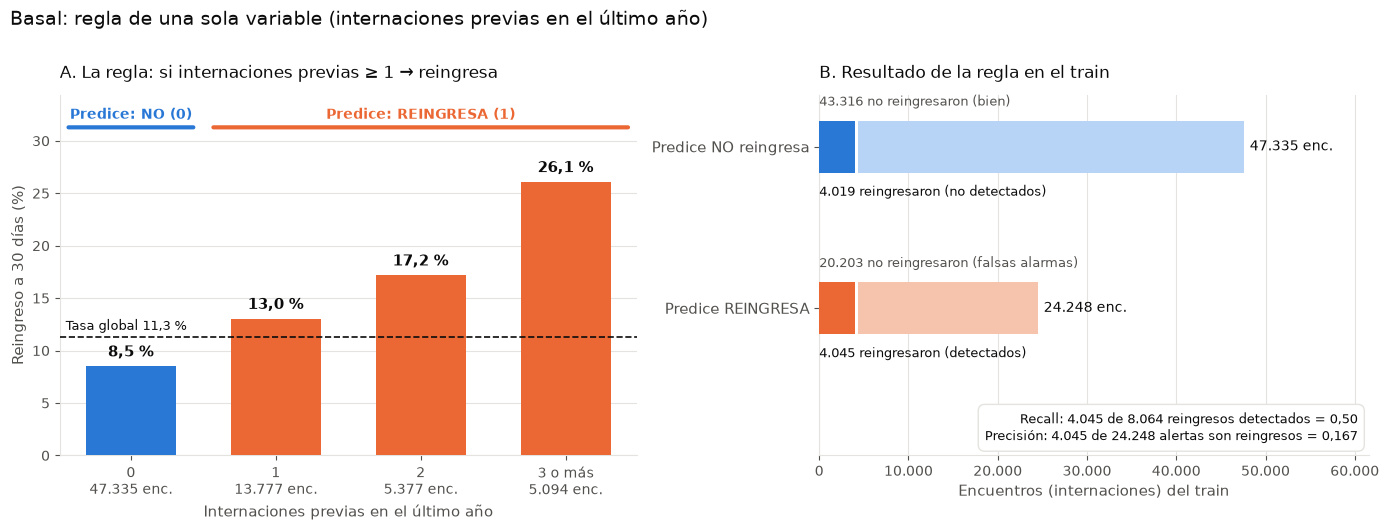

In [7]:
AZUL, NARANJA = "#2a78d6", "#eb6834"          # predice 0 / predice 1
AZUL_CLARO, NARANJA_CLARO = "#b7d3f6", "#f6c3ad"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"


def fmt_n(x):
    return f"{int(round(x)):,}".replace(",", ".")


def fmt_pct(x):
    return f"{x * 100:.1f} %".replace(".", ",")


def graficar_regla_basal(niveles, n_enc, n_pos, k):
    """niveles: etiquetas; n_enc: encuentros por nivel; n_pos: reingresos por nivel; k: corte (código de nivel)."""
    n_enc, n_pos = np.asarray(n_enc, float), np.asarray(n_pos, float)
    tasas = n_pos / n_enc
    base = n_pos.sum() / n_enc.sum()
    pred1 = np.arange(len(niveles)) >= k

    fig, (axA, axB) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.05, 1]})
    fig.patch.set_facecolor("white")

    # ---------- Panel A: la regla ----------
    x = np.arange(len(niveles))
    axA.bar(x, tasas * 100, width=0.62, color=[NARANJA if p else AZUL for p in pred1], zorder=3)
    for xi, t in zip(x, tasas):
        axA.text(xi, t * 100 + 0.6, fmt_pct(t), ha="center", va="bottom", fontsize=11,
                 color=TINTA, fontweight="bold")
    axA.axhline(base * 100, color=TINTA, ls="--", lw=1.2, zorder=4)
    axA.text(-0.45, base * 100 + 0.4, f"Tasa global {fmt_pct(base)}",
             ha="left", va="bottom", fontsize=9.5, color=TINTA)
    axA.set_xticks(x)
    axA.set_xticklabels([f"{nv}\n{fmt_n(n)} enc." for nv, n in zip(niveles, n_enc)], fontsize=10)
    axA.set_xlabel("Internaciones previas en el último año", fontsize=10.5, color=TINTA_2)
    axA.set_ylabel("Reingreso a 30 días (%)", fontsize=10.5, color=TINTA_2)
    axA.set_ylim(0, max(tasas) * 100 * 1.32)
    # franja de decisión arriba de las barras
    ytop = max(tasas) * 100 * 1.20
    axA.annotate("", xy=(k - 0.45, ytop), xytext=(len(niveles) - 0.55, ytop),
                 arrowprops=dict(arrowstyle="-", color=NARANJA, lw=3))
    axA.text((k + len(niveles) - 1) / 2, ytop + 0.5, "Predice: REINGRESA (1)",
             ha="center", va="bottom", fontsize=10, color=NARANJA, fontweight="bold")
    if k > 0:
        axA.annotate("", xy=(-0.45, ytop), xytext=(k - 0.55, ytop),
                     arrowprops=dict(arrowstyle="-", color=AZUL, lw=3))
        axA.text((k - 1) / 2, ytop + 0.5, "Predice: NO (0)",
                 ha="center", va="bottom", fontsize=10, color=AZUL, fontweight="bold")
    axA.set_title(f"A. La regla: si internaciones previas ≥ {k} → reingresa",
                  loc="left", fontsize=12.5, color=TINTA, pad=12)

    # ---------- Panel B: qué pasa al aplicarla ----------
    grupos = [("Predice NO reingresa", ~pred1, AZUL, AZUL_CLARO),
              ("Predice REINGRESA", pred1, NARANJA, NARANJA_CLARO)]
    y = np.array([1.7, 0])
    tot_pos = n_pos.sum()
    vp = n_pos[pred1].sum()
    pred_pos = n_enc[pred1].sum()
    for yi, (nombre, m, c_osc, c_cla) in zip(y, grupos):
        pos, tot = n_pos[m].sum(), n_enc[m].sum()
        neg = tot - pos
        axB.barh(yi, pos, height=0.55, color=c_osc, zorder=3)
        axB.barh(yi, neg, left=pos + 300, height=0.55, color=c_cla, zorder=3)
        etiqueta_pos = "reingresaron (detectados)" if nombre.endswith("REINGRESA") else "reingresaron (no detectados)"
        etiqueta_neg = "no reingresaron (falsas alarmas)" if nombre.endswith("REINGRESA") else "no reingresaron (bien)"
        axB.text(pos + 300 + neg + 600, yi, f"{fmt_n(tot)} enc.", va="center", fontsize=10, color=TINTA)
        axB.text(0, yi - 0.40, f"{fmt_n(pos)} {etiqueta_pos}", va="top", fontsize=9.5, color=TINTA)
        axB.text(0, yi + 0.40, f"{fmt_n(neg)} {etiqueta_neg}", va="bottom", fontsize=9.5, color=TINTA_2)
    axB.set_yticks(y)
    axB.set_yticklabels([g[0] for g in grupos], fontsize=10.5, color=TINTA)
    axB.set_ylim(-1.55, 2.25)
    axB.set_xlim(0, n_enc.sum() * 0.86)
    axB.set_xlabel("Encuentros (internaciones) del train", fontsize=10.5, color=TINTA_2)
    axB.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt_n(v)))
    axB.set_title("B. Resultado de la regla en el train", loc="left", fontsize=12.5, color=TINTA, pad=12)
    dec = lambda v, d: f"{v:.{d}f}".replace(".", ",")
    texto = (f"Recall: {fmt_n(vp)} de {fmt_n(tot_pos)} reingresos detectados = {dec(vp / tot_pos, 2)}\n"
             f"Precisión: {fmt_n(vp)} de {fmt_n(pred_pos)} alertas son reingresos = {dec(vp / pred_pos, 3)}")
    axB.text(0.98, 0.03, texto, transform=axB.transAxes,
             ha="right", va="bottom", fontsize=9.5, color=TINTA,
             bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=GRILLA))

    for ax in (axA, axB):
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        for s in ("left", "bottom"):
            ax.spines[s].set_color(GRILLA)
        ax.tick_params(colors=TINTA_2)
    axA.yaxis.grid(True, color=GRILLA, zorder=0)
    axB.xaxis.grid(True, color=GRILLA, zorder=0)
    fig.suptitle("Basal: regla de una sola variable (internaciones previas en el último año)",
                 fontsize=14, color=TINTA, x=0.01, ha="left", y=1.01)
    plt.tight_layout()
    return fig


_x = Xm_train[VAR_BASAL].astype(object).to_numpy()
_y = y_ent.to_numpy()
n_enc = pd.Series(_x).value_counts().reindex(NIVELES_BASAL).to_numpy()
n_pos = pd.Series(_y).groupby(_x).sum().reindex(NIVELES_BASAL).to_numpy()
fig = graficar_regla_basal(["0", "1", "2", "3 o más"], n_enc, n_pos, k_final)
plt.show()

**Lectura.** La tasa de reingreso crece con las internaciones previas: 8,5 % sin ninguna, 13,0 % con una,
17,2 % con dos y 26,1 % con tres o más, frente a una tasa global de 11,3 % (la línea punteada del panel A).
Solo el nivel 0 queda por debajo de la tasa global, así que en los cinco folds el corte resulta el mismo, k = 1:

> **Un paciente con al menos una internación en el año previo se clasifica como "reingresa".**

Para un paciente nuevo alcanza con contar sus internaciones del último año. Los números bajo las barras son
internaciones del train, no pacientes distintos: un mismo paciente puede aportar varias.

El panel B muestra el costo de la regla. De las 47.335 internaciones sin antecedentes, que la regla clasifica
como "no reingresa", 4.019 sí reingresaron y quedan sin detectar. De las 24.248 que marca como "reingresa",
4.045 reingresaron y el resto son falsas alarmas. Por eso detecta la mitad de los reingresos (recall 0,50) y
solo una de cada seis alertas es correcta (precisión 0,167).

En validación cruzada la regla logra un ROC-AUC de 0,606 y un AUC-PR de 0,161, contra 0,5 y 0,113 de la
prevalencia, con F1 0,250 y exactitud balanceada 0,592. Su techo es claro: distingue solo cuatro grupos y usa
una sola variable, mientras que un algoritmo puede separar pacientes dentro de un mismo nivel combinando el
resto de la información. Este es el número a superar: un algoritmo que no mejore claramente un ROC-AUC de
0,606 no justifica su complejidad.

### ¿Por qué el corte en la tasa global?

La regla tiene un solo número que decidir, el corte k. Con cuatro niveles, las opciones posibles son k = 1, 2
o 3. Para mostrar qué implica cada una, evaluamos las tres con los mismos folds. No es una búsqueda del mejor
corte: el criterio (la tasa global) quedó fijado antes, y esta tabla solo muestra qué se gana y qué se pierde
al moverlo.

In [8]:
filas_k = []
for k_alt in [1, 2, 3]:
    for f, (tr, va) in enumerate(pares(42)):
        nivel_va, pred_va = aplicar_regla(Xm_train[VAR_BASAL].iloc[va], k_alt)
        filas_k.append({"corte k": k_alt, "fold": f + 1, **metricas(y_ent.iloc[va], nivel_va, pred_va)})
cortes = pd.DataFrame(filas_k).groupby("corte k").mean().drop(columns="fold")
cortes.insert(0, "regla", ["al menos 1 internación previa", "al menos 2 internaciones previas",
                           "al menos 3 internaciones previas"])
cortes.round(3)

,regla,ROC-AUC,AUC-PR,recall,precisión,F1,exactitud balanceada
corte k,,,,,,,
1,al menos 1 internación previa,0.606,0.161,0.502,0.167,0.250,0.592
2,al menos 2 internaciones previas,0.606,0.161,0.279,0.215,0.243,0.575
3,al menos 3 internaciones previas,0.606,0.161,0.165,0.261,0.202,0.553


**Lectura.** Subir el corte vuelve la regla más exigente. Las alertas son algo más certeras (la precisión
pasa de 0,17 con k = 1 a 0,26 con k = 3), pero se pierden muchos reingresos: el recall cae de 0,50 a 0,17. El
corte k = 1, que es el que surge de comparar con la tasa global, es también el de mejor F1 (0,250) y mejor
exactitud balanceada (0,592), así que el criterio elegido coincide con el corte más equilibrado.

El ROC-AUC y el AUC-PR no cambian, porque no dependen del corte sino del orden de los pacientes, que es el
mismo en las tres versiones. Por eso el número a superar por los modelos no depende de esta decisión.

### Chequeo confirmatorio de la variable del basal

La variable del basal se eligió por el ranking del EDA. Como confirmación, comparamos cómo ordena a los
pacientes por riesgo una regla de una sola variable armada con cada una de tres candidatas:
`number_inpatient_disc`, `patient_nbr_ordinal` y `discharge_disposition_id`.

Para que la comparación sea justa usamos el mismo procedimiento con las tres: cada nivel de la variable
recibe como puntaje su tasa de reingreso en el train del fold, y con ese puntaje se calcula el ROC-AUC fuera de
fold. Hace falta porque `discharge_disposition_id` tiene 26 categorías sin un orden natural, y la tasa es la
forma razonable de ordenarlas por riesgo. Para `number_inpatient_disc` este puntaje da exactamente el mismo
ROC-AUC que la regla de M1, porque las tasas crecen en el mismo orden que los niveles: no es un basal
distinto, es la misma regla vista desde el orden que produce. Los niveles con menos de 200 filas en el train
del fold se agrupan en "otros" (con 11 % de positivos, 200 filas dejan unos 22 positivos por nivel).

**Criterio, declarado antes de mirar el resultado:** otra candidata le gana a `number_inpatient_disc` solo si
la diferencia media de ROC-AUC (candidata menos referencia) es positiva y mayor que el desvío entre folds de
esa diferencia. Se usan las cuatro repeticiones de folds (20 evaluaciones, que no son independientes entre sí).
Si otra candidata gana, se informa y no se cambia la variable por decisión propia.

,ROC-AUC medio,desvío entre folds,diferencia media vs. basal,desvío de la diferencia,¿le gana al basal?
variable,,,,,
number_inpatient_disc,0.6061,0.0057,NaN,NaN,NaN
patient_nbr_ordinal,0.5954,0.0058,-0.0106,0.0037,no
discharge_disposition_id,0.5868,0.0069,-0.0193,0.0089,no


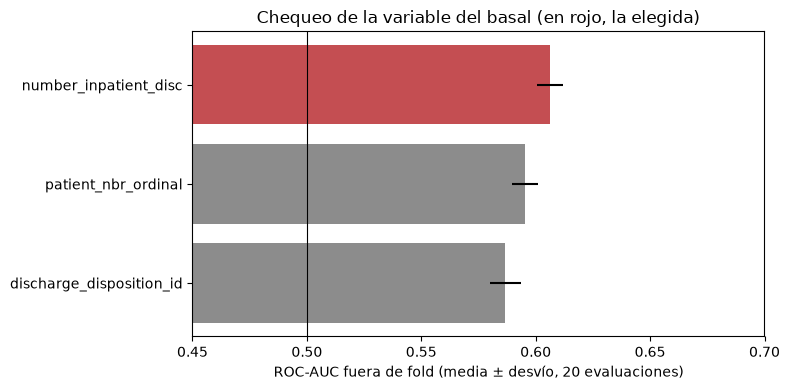

In [9]:
CANDIDATAS = {"number_inpatient_disc": None,
              "patient_nbr_ordinal": None,
              "discharge_disposition_id": 200}      # n_min: niveles con menos filas se agrupan en "otros"

filas = []
for var, n_min in CANDIDATAS.items():
    for semilla in SEMILLAS_CV:
        for k, (tr, va) in enumerate(pares(semilla)):
            _, s_va = puntaje_tabla(var, tr, va, n_min)
            auc = roc_auc_score(y_ent.iloc[va], s_va)
            filas.append({"variable": var, "semilla": semilla, "fold": k + 1, "ROC-AUC": auc})
            registrar(fase="M1-chequeo", algoritmo=f"tabla {var}", semilla=semilla, fold=k + 1, **{"ROC-AUC": auc})
chequeo = pd.DataFrame(filas)
ancho = chequeo.pivot_table(index=["semilla", "fold"], columns="variable", values="ROC-AUC")

resumen_chequeo = pd.DataFrame({"ROC-AUC medio": ancho.mean(), "desvío entre folds": ancho.std()})
for var in ancho.columns:
    if var != VAR_BASAL:
        dif = ancho[var] - ancho[VAR_BASAL]
        resumen_chequeo.loc[var, "diferencia media vs. basal"] = dif.mean()
        resumen_chequeo.loc[var, "desvío de la diferencia"] = dif.std()
        resumen_chequeo.loc[var, "¿le gana al basal?"] = "SÍ" if (dif.mean() > 0 and dif.mean() > dif.std()) else "no"
display(resumen_chequeo.sort_values("ROC-AUC medio", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
orden = resumen_chequeo.sort_values("ROC-AUC medio").index
ax.barh(orden, resumen_chequeo.loc[orden, "ROC-AUC medio"], xerr=resumen_chequeo.loc[orden, "desvío entre folds"],
        color=["#C44E52" if v == VAR_BASAL else "#8C8C8C" for v in orden])
ax.axvline(0.5, color="black", lw=0.8)
ax.set_xlim(0.45, max(0.7, resumen_chequeo["ROC-AUC medio"].max() + 0.03))
ax.set_xlabel("ROC-AUC fuera de fold (media ± desvío, 20 evaluaciones)")
ax.set_title("Chequeo de la variable del basal (en rojo, la elegida)")
plt.tight_layout()
plt.show()
guardar_registro()

**Lectura.** El criterio declarado se cumple: ninguna candidata le gana a `number_inpatient_disc`, que queda
confirmada como variable del basal. Obtiene un ROC-AUC de 0,606, el mismo de la regla de M1, por encima de
`patient_nbr_ordinal` (0,595) y de `discharge_disposition_id` (0,587). La diferencia con `patient_nbr_ordinal`
(−0,011) es mayor que su desvío (0,004), así que no es ruido, y la de `discharge_disposition_id` (−0,019) es
la más variable (desvío 0,009). `discharge_disposition_id` encabezaba la asociación en la sección 3.6 (notebook 1), pero
allí se medía contra el target de tres clases y todavía no existían las variables derivadas; usada sola, como
tabla de 26 niveles con los raros agrupados, discrimina menos que el historial de internaciones.

## 8.2 M2: Definición formal

- **Problema.** Clasificación binaria supervisada: determinar si un paciente diabético reingresa en los 30
  días siguientes al alta (`readmitted_temprano`). El modelo se concibe para aplicarse al alta, con las 18
  variables seleccionadas en el EDA.
- **Métrica primaria.** ROC-AUC, porque compara la capacidad de ordenar a los pacientes por riesgo sin fijar un
  umbral. **Métricas secundarias:** recall, precisión, F1, exactitud balanceada y AUC-PR. Las que dependen de
  una decisión usan el umbral elegido con predicciones fuera de fold en train.
- **Costo de los errores.** No está cuantificado, y por eso no se define un punto de operación. Que un falso
  negativo cueste más que un falso positivo es un supuesto cualitativo que viene del planteo del dataset (el
  reingreso aumenta los costos y la morbimortalidad).
- **Criterio de éxito, declarado antes de ver los resultados de los algoritmos.** Un algoritmo supera al
  basal cuando su ROC-AUC medio de validación cruzada es mayor que el del basal por más que el desvío entre
  folds de la diferencia pareada, y esa diferencia es positiva en todos los folds de la repetición principal.
  Si ningún algoritmo lo logra, el resultado se informa como negativo y se discuten sus causas.
- **Restricciones.** No se exige interpretabilidad ni latencia. Las variables son las disponibles al alta.
  La regresión logística aporta una referencia interpretable.

## 8.3 M3: Estrategia de validación

Validación cruzada de 5 folds, estratificada por el target y **agrupada por paciente**, solo sobre el train.
Agrupamos por paciente porque un mismo
paciente tiene varias internaciones y, si quedaran repartidas entre entrenamiento y validación, la validación
sería optimista. La misma estrategia vale para el basal y para los cuatro algoritmos. Se verifica que
ningún paciente aparezca en dos folds de validación, ni en el entrenamiento y la validación de un mismo
fold, y que la tasa de positivos sea pareja.

Verificación superada en las 4 repeticiones: ningún paciente en dos folds ni compartido con el entrenamiento.


,filas de validación,pacientes de validación,positivos,tasa de positivos (%),pacientes compartidos con el entrenamiento
fold,,,,,
1,14317,9990,1613,11.27,0
2,14318,9968,1613,11.27,0
3,14316,10000,1613,11.27,0
4,14316,10035,1613,11.27,0
5,14316,10067,1612,11.26,0


Resumen de las 4 repeticiones (tasa de positivos por fold, %):


,min,max
semilla,,
42,11.26,11.27
43,11.25,11.28
44,11.26,11.27
45,11.26,11.27


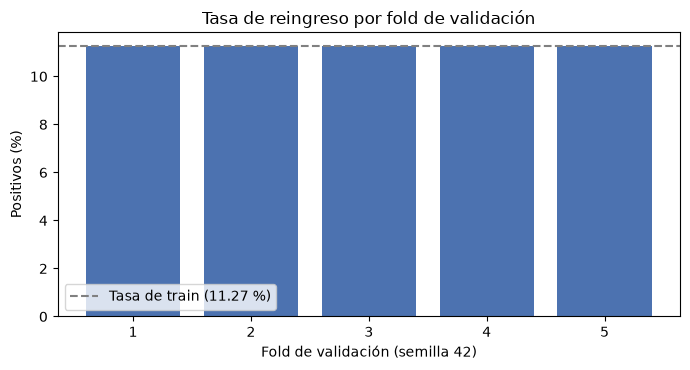

In [10]:
filas = []
for semilla in SEMILLAS_CV:
    ids = FOLD_ID[semilla]
    # cada paciente en un único fold de validación
    n_folds_por_paciente = pd.Series(ids).groupby(pacientes).nunique()
    assert n_folds_por_paciente.max() == 1, f"hay pacientes en más de un fold (semilla {semilla})"
    for k, (tr, va) in enumerate(pares(semilla)):
        compartidos = len(set(pacientes[tr]) & set(pacientes[va]))
        assert compartidos == 0, f"pacientes compartidos entre entrenamiento y validación (semilla {semilla}, fold {k+1})"
        filas.append({"semilla": semilla, "fold": k + 1, "filas de validación": len(va),
                      "pacientes de validación": len(set(pacientes[va])),
                      "positivos": int(y_ent.iloc[va].sum()),
                      "tasa de positivos (%)": round(y_ent.iloc[va].mean() * 100, 2),
                      "pacientes compartidos con el entrenamiento": compartidos})
diag_folds = pd.DataFrame(filas)
print("Verificación superada en las 4 repeticiones: ningún paciente en dos folds ni compartido con el entrenamiento.")
display(diag_folds[diag_folds["semilla"] == 42].set_index("fold").drop(columns="semilla"))
print("Resumen de las 4 repeticiones (tasa de positivos por fold, %):")
display(diag_folds.groupby("semilla")["tasa de positivos (%)"].agg(["min", "max"]))

fig, ax = plt.subplots(figsize=(7, 3.8))
d42 = diag_folds[diag_folds["semilla"] == 42]
ax.bar(d42["fold"].astype(str), d42["tasa de positivos (%)"], color="#4C72B0")
ax.axhline(y_ent.mean() * 100, color="gray", ls="--", label=f"Tasa de train ({y_ent.mean()*100:.2f} %)")
ax.set_xlabel("Fold de validación (semilla 42)")
ax.set_ylabel("Positivos (%)")
ax.set_title("Tasa de reingreso por fold de validación")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.** La validación cumple lo exigido. Ningún paciente aparece en dos folds de validación ni compartido
con el entrenamiento de su fold, en las cuatro repeticiones. Los folds son parejos: entre 14.316 y 14.318
filas y entre 1.612 y 1.613 positivos cada uno, con una tasa de 11,26 a 11,27 % (11,25 a 11,28 % en las otras
semillas), igual a la del train. Es la estrategia que usan el basal y, desde M4, los cuatro algoritmos.

### 8.3.1 Chequeo de sensibilidad de la selección de variables

La selección de las 18 variables (sección 6 del notebook 1) se hizo con todo el train, es decir, fuera de los folds. Las 18
quedan fijas como modelo, pero se mide cuánto depende esa elección de qué filas se usan: **la regla de
relevancia de la sección 6.1 se repite en el train de cada uno de los 20 folds** (4 repeticiones por 5 folds)
y se compara el resultado con el del EDA. La regla es la misma: se descarta una variable solo si queda en el
tercio inferior del criterio de su tipo (ANOVA F si es numérica, V de Cramér si es categórica) **y** de la
información mutua. A eso se suman las decisiones fijas de 6.3 (`change`, `diabetesMed`, y las dos numéricas
reemplazadas por su versión discretizada). La redundancia automática por V ≥ 0,7 no se repite: en el EDA
ningún par llegó a ese valor (el máximo fue 0,64).

Es un diagnóstico, no parte del modelo: si la selección fuera inestable, el desempeño de la validación cruzada
estaría algo inflado, porque cada fold de validación habría participado en elegir las variables.

In [11]:
from sklearn.feature_selection import f_classif, mutual_info_classif
from scipy.stats import chi2_contingency

NUM_32, CAT_32 = list(num_orig), list(cat_orig)
FIJAS = {"change", "diabetesMed", "number_emergency", "number_inpatient"}      # decisiones de 6.3, no dependen de la muestra
SELECCION_EDA = set(variables_seleccionadas)


def seleccion_en_fold(idx_tr):
    Xf, yf = X_train.iloc[idx_tr], y_ent.iloc[idx_tr]
    F, _ = f_classif(Xf[NUM_32].astype(float), yf)
    V = {}
    for c in CAT_32:
        tabla = pd.crosstab(Xf[c], yf)
        chi2 = chi2_contingency(tabla)[0]
        k = min(tabla.shape) - 1
        V[c] = np.sqrt(chi2 / (tabla.to_numpy().sum() * k)) if k > 0 else np.nan
    X_mi = pd.concat([Xf[NUM_32].astype(float), Xf[CAT_32].apply(lambda s: s.cat.codes.astype(int))], axis=1)
    mi = mutual_info_classif(X_mi, yf, discrete_features=np.array([False] * len(NUM_32) + [True] * len(CAT_32)),
                             random_state=SEMILLA)
    rel = pd.DataFrame({"variable": NUM_32 + CAT_32,
                        "tipo": ["num"] * len(NUM_32) + ["cat"] * len(CAT_32),
                        "criterio": list(F) + [V[c] for c in CAT_32], "mi": mi})
    rel["pct_tipo"] = rel.groupby("tipo")["criterio"].rank(pct=True)
    rel["pct_mi"] = rel.groupby("tipo")["mi"].rank(pct=True)
    debiles = set(rel.loc[(rel["pct_tipo"] <= 1 / 3) & (rel["pct_mi"] <= 1 / 3), "variable"])
    return set(NUM_32 + CAT_32) - debiles - FIJAS


selecciones = []
for semilla in SEMILLAS_CV:
    for k, (tr, va) in enumerate(pares(semilla)):
        selecciones.append(seleccion_en_fold(tr))
iguales = sum(s == SELECCION_EDA for s in selecciones)

frecuencia = pd.Series({v: np.mean([v in s for s in selecciones]) for v in NUM_32 + CAT_32})
tabla_sel = pd.DataFrame({"decisión del EDA": ["conservada" if v in SELECCION_EDA else "descartada" for v in frecuencia.index],
                          "% de los 20 folds en que se conserva": (frecuencia * 100).round(0).astype(int)})
inestables = tabla_sel[(tabla_sel["% de los 20 folds en que se conserva"] > 0) &
                       (tabla_sel["% de los 20 folds en que se conserva"] < 100)]
registrar(fase="M3-selección", algoritmo="regla de selección", folds_con_las_mismas_18=iguales, folds=len(selecciones))
guardar_registro()
print(f"Folds en los que la regla reproduce exactamente las 18 variables del EDA: {iguales} de {len(selecciones)}")
print(f"Variables que cambian de decisión según el fold: {len(inestables)}")
inestables.sort_values("% de los 20 folds en que se conserva")

Folds en los que la regla reproduce exactamente las 18 variables del EDA: 3 de 20
Variables que cambian de decisión según el fold: 5


,decisión del EDA,% de los 20 folds en que se conserva
max_glu_serum,descartada,5
admission_type_id,descartada,15
number_outpatient,descartada,40
num_procedures,descartada,50
num_lab_procedures,conservada,90


**Lectura.** La regla reproduce exactamente las 18 variables del EDA en solo 3 de los 20 folds, pero la
diferencia sale de cinco variables marginales, que cambian de decisión según la muestra: `num_lab_procedures`
(se conserva en el 90 % de los folds), `num_procedures` (50 %), `number_outpatient` (40 %), `admission_type_id`
(15 %) y `max_glu_serum` (5 %). Las otras 27 variables toman siempre la misma decisión: 17 se conservan en
todos los folds y 10 se descartan en todos. Es lo esperable en variables que están cerca del tercio inferior del
ranking, donde una muestra distinta las cruza de un lado o del otro, y ninguna de las cinco está entre las
variables más importantes (en M8, notebook 4, `num_lab_procedures` aporta una caída de ROC-AUC de 0,0002 a 0,0004).

Esto indica que elegir las variables con todo el train no infla de forma apreciable la validación cruzada:
las variables que dependen de la muestra casi no aportan señal, y las que sí aportan (el tipo de alta y los
antecedentes de internación) se eligen en todos los folds. Se declara como una limitación menor del diseño.

---
## Cierre del notebook 2

Quedan fijados el criterio de éxito y la vara a superar: una regla de una sola variable (al menos una
internación en el año previo implica reingreso) que logra un ROC-AUC de 0,606 en validación cruzada. Los folds
agrupados por paciente están guardados y se reutilizan sin cambios en el resto del trabajo.

El notebook 3 entrena los cuatro algoritmos sobre esos mismos folds.

---
### Estado de la sesión para el notebook siguiente

Se guarda el estado completo de la sesión (datos, variables y funciones definidas hasta acá) para que el
notebook siguiente continúe exactamente desde este punto, sin repetir los cálculos. El archivo queda en
`artefactos_ml/` y no se sube al repositorio por su tamaño.

In [12]:
import dill
from pathlib import Path
Path("artefactos_ml").mkdir(exist_ok=True)
dill.dump_session("artefactos_ml/estado_02.pkl")
dill.extend(False)            # deja el pickle estándar como estaba
print("Estado guardado en artefactos_ml/estado_02.pkl")

Estado guardado en artefactos_ml/estado_02.pkl
